# Time series: motif

## Motif discovery 
**Motif**: a repeated pattern in the time series. We can discover motif by computing the Matrix Profile: a data structure that annotates time series by using a sliding window to compare the pairwise distance among the subsequences.

### Matrix Profile
You can use these packages:
    
    
https://github.com/target/matrixprofile-ts

https://github.com/TDAmeritrade/stumpy

In [1]:
import math
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import pdist, squareform

from matrixprofile import *

data_path = './data_notebook/data/'

In [2]:
df = pd.read_csv(f'{data_path}air_passengers.csv', parse_dates=True, index_col='Month', date_format='%Y-%m')
df.head()

,#Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


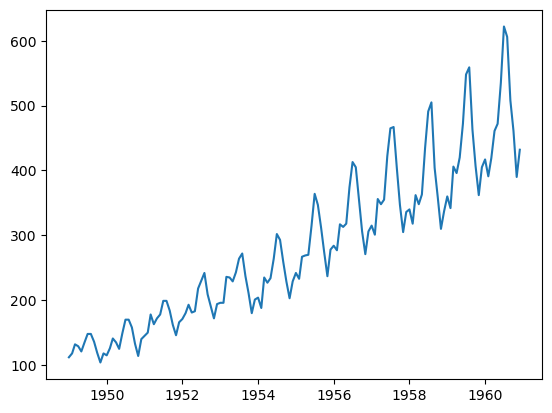

In [3]:
ts = df['#Passengers']
plt.plot(ts)
plt.show()

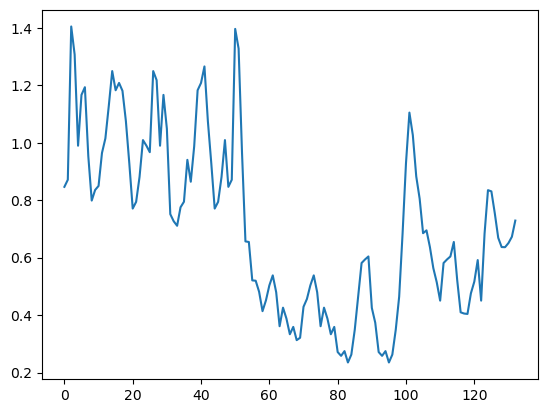

In [4]:
w = 12
mp, mpi = matrixProfile.stomp(ts.values, w)

plt.plot(mp)
plt.show()

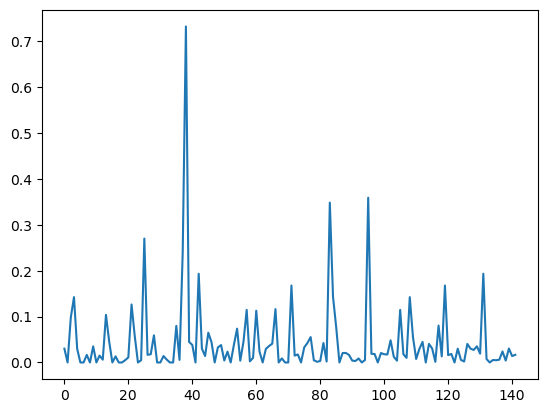

In [5]:
w = 3
mp, mpi = matrixProfile.stomp(ts.values, w)

plt.plot(mp)
plt.show()

### Motif discovery
Parameters:
- `max_motifs`: stop finding new motifs once we have max_motifs
- `radius`: For each motif found, find neighbors that are within $radius * motif_{mp}$ of the first.
- `n_neighbors`: number of neighbors from the first to find. If it is None, find all.
- `ex_zone`: minimum distance between indices for after each subsequence is identified. Defaults to m/2 where m is the subsequence length. If ex_zone = 0, only the found index is exclude, if ex_zone = 1 then if idx is found as a motif idx-1, idx, idx+1 are excluded.


The function returns a tuple (top_motifs, distances) which are lists of the same length.

- `top_motifs`: This is a list of the indices found for each motif. The first index is the nth motif followed by all nearest neighbors found sorted by distances.
- `distances`: Minimum Matrix profile value for each motif set.

In [6]:
mo, mod  = motifs.motifs(ts.values, (mp, mpi), max_motifs=5)

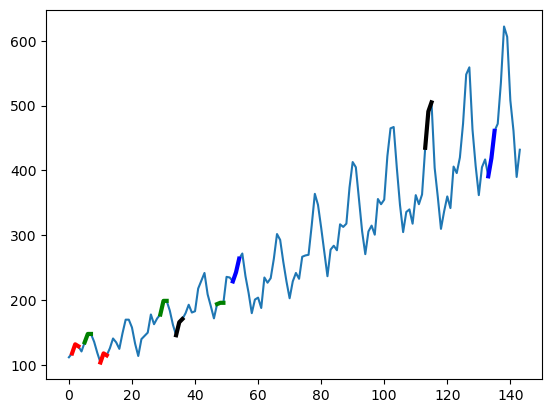

In [7]:
plt.plot(ts.values)
colors = ['r', 'g', 'k', 'b', 'y'][:len(mo)]
for m, d, c in zip(mo, mod, colors):
    for i in m:
        m_shape = ts.values[i:i+w]
        plt.plot(range(i,i+w), m_shape, color=c, lw=3)

plt.show()

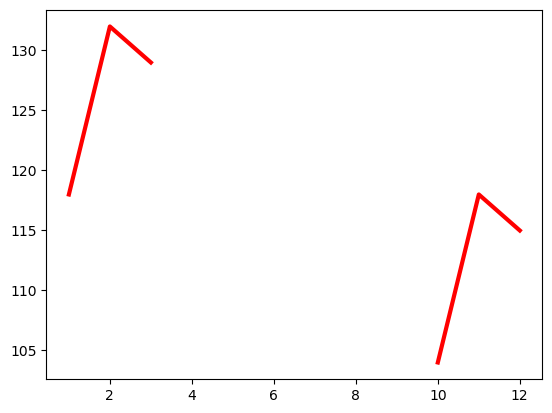

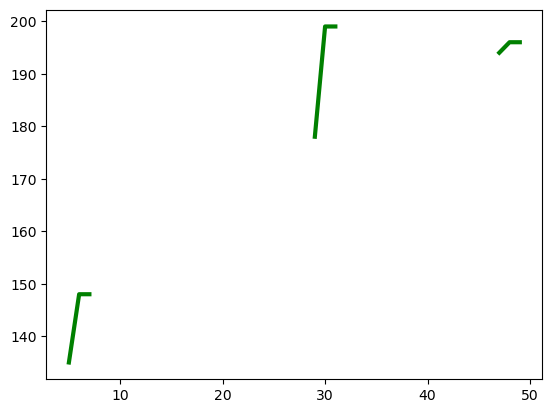

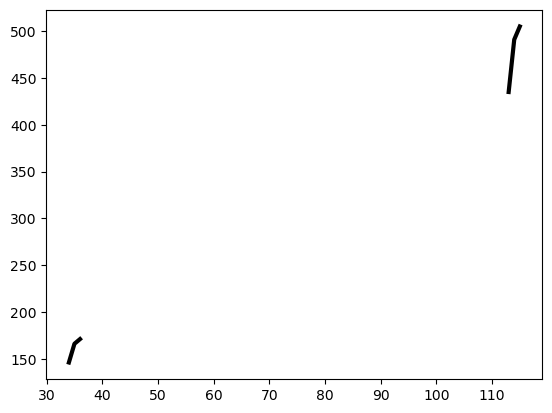

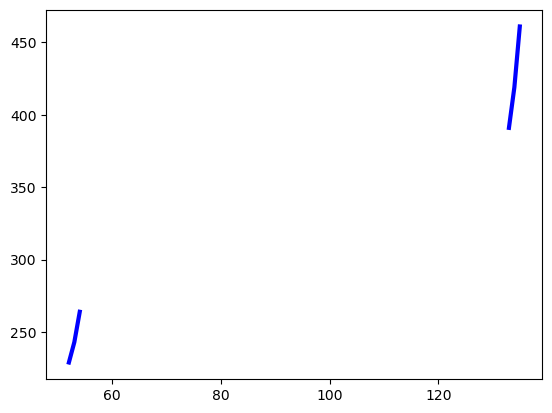

In [8]:
for m, d, c in zip(mo, mod, colors):
    for i in m:
        m_shape = ts.values[i:i+w]
        plt.plot(range(i,i+w), m_shape, color=c, lw=3)
    plt.show()

### Anomaly Discovery
Parameters:
- `mp`: matrix profile numpy array
- `k`: the number of discords to discover
- `ex_zone`: the number of samples to exclude and set to Inf on either side of a found discord 


An exclusion zone in time series matrix profile analysis is a range of neighboring indices around a given subsequence that is ignored during nearest-neighbor search. It prevents the algorithm from matching a subsequence with its own overlapping or adjacent self-matches, which are called *trivial matches*.


- Trivial Matches: Because a matrix profile slides a window across continuous time series data (step-by-step by 1 index), a window at time step t shares almost all of its data points with the window at time step t+1 or t-1.
- Avoiding False Results: Without an exclusion zone, every subsequence would trivially find its immediate neighbor just a few steps away with a distance close to zero, making it impossible to find true repeated patterns (motifs) or genuine structural outliers (discords/anomalies).


Returns a list of indexes represent the discord starting locations. `MaxInt` indicates there were no more discords that could be found due to too many exclusions or profile being too small. Discord start indices are sorted by highest matrix profile value.

In [9]:
from matrixprofile.discords import discords
anoms = discords(mp, ex_zone=3, k=5)

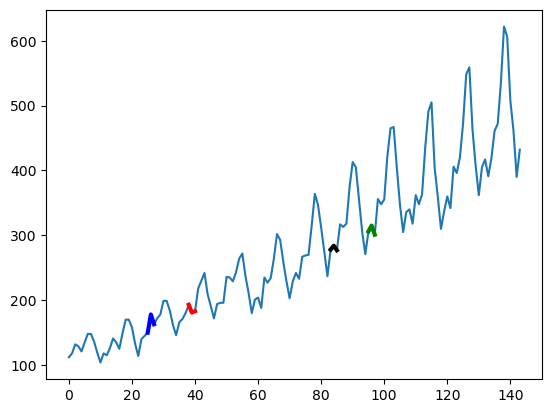

In [10]:
plt.plot(ts.values)
colors = ['r', 'g', 'k', 'b', 'y'][:len(mo)]
for a, c in zip(anoms, colors):
    a_shape = ts.values[a:a+w]
    plt.plot(range(a, a+w), a_shape, color=c, lw=3)

plt.show()